In [14]:
import pandas as pd
import matplotlib.pyplot as plt
# import numpy as np
from sklearn.model_selection import train_test_split
# from sklern.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import classification_report, f1_score, confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve, auc
from sklearn.linear_model import LogisticRegression
import seaborn as sns
# from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import StandardScaler
# from sklearn.preprocessing import OrdinalEncoder
from imblearn.over_sampling import SMOTENC


In [17]:
dataframe= pd.read_csv("dataset_1&2combined.csv")
print(dataframe.head())
print(dataframe.shape)
print(dataframe.describe())
print(dataframe.info())
print(dataframe.isnull().sum())
print(dataframe.dtypes)
print(dataframe.duplicated().sum())
print(dataframe.select_dtypes(include=["object", "category"]).columns.tolist())

   patient_file_no  pcos_label  age_years  weight_kg   height_cm        bmi  \
0              193           0         30  69.979147  167.708055  23.185569   
1              360           0         36  63.711688  154.055877  25.441392   
2               10           0         36  51.848631  149.059804  23.928264   
3              278           1         29  66.893988  148.628036  27.894935   
4               71           0         33  52.536198  150.767409  23.079564   

   blood_group_code  pulse_bpm  resp_rate  hemoglobin  ...  \
0                12         72         22        12.0  ...   
1                13         70         18        10.5  ...   
2                15         80         20        10.0  ...   
3                15         72         18        12.0  ...   
4                13         72         18        10.2  ...   

  ayurveda_choice_reasons  ayurveda_treatment_forms  \
0          Not_applicable                  Not_used   
1                   Other        Decoction

In [54]:
dataframe["cycle_regularity"] = (dataframe["cycle_regularity"].map({"Regular": 0, "Irregular": 1}))
print(dataframe["cycle_regularity"].value_counts(dropna=False))
dataframe["yoga_practiced"] = (dataframe["yoga_practiced"].map({"Yes": 0, "No": 1}))
print(dataframe["yoga_practiced"].value_counts(dropna=False))

drop_columns = ["weight_kg", "height_cm", "patient_file_no", "blood_group_code", "pulse_bpm",
                "resp_rate", "pregnancy_flag", "beta_hcg_1", "fsh_lh_ratio", "hip_in", "waist_in",
                "whr","diets_tried", "vitamin_d3", "bp_systolic", "bp_diastolic", "beta_hcg_2", "beta_hcg_2_imputed",
                "amh_imputed", "marriage_duration_years_imputed", "cycle_regularity_imputed",
                "rotterdam_phenotype", "exercise_forms_helpful", "tcm_systems_tried",
                "ayurveda_first_visit_timing", "ayurveda_use_duration", "ayurveda_decision_influence",
                "ayurveda_choice_reasons", "ayurveda_treatment_forms", "ayurveda_adverse_reaction",
                "yoga_nonuse_reasons", "yoga_future_interest", "yoga_duration", "yoga_reasons", "yoga_style",
                "yoga_elements"]


cycle_regularity
NaN    530
Name: count, dtype: int64
yoga_practiced
NaN    530
Name: count, dtype: int64


In [55]:
existing_columns = [
    col for col in drop_columns
    if col in dataframe.columns
]

missing_columns = [
    col for col in drop_columns
    if col not in dataframe.columns
]

print("Columns available for removal:", existing_columns)
print("Columns not found:", missing_columns)


Columns available for removal: ['diets_tried']
Columns not found: ['weight_kg', 'height_cm', 'patient_file_no', 'blood_group_code', 'pulse_bpm', 'resp_rate', 'pregnancy_flag', 'beta_hcg_1', 'fsh_lh_ratio', 'hip_in', 'waist_in', 'whr', 'vitamin_d3', 'bp_systolic', 'bp_diastolic', 'beta_hcg_2', 'beta_hcg_2_imputed', 'amh_imputed', 'marriage_duration_years_imputed', 'cycle_regularity_imputed', 'rotterdam_phenotype', 'exercise_forms_helpful', 'tcm_systems_tried', 'ayurveda_first_visit_timing', 'ayurveda_use_duration', 'ayurveda_decision_influence', 'ayurveda_choice_reasons', 'ayurveda_treatment_forms', 'ayurveda_adverse_reaction', 'yoga_nonuse_reasons', 'yoga_future_interest', 'yoga_duration', 'yoga_reasons', 'yoga_style', 'yoga_elements']


In [57]:
# Drop only the columns that actually exist in the dataframe
dataframe = dataframe.drop(columns=existing_columns)

print(dataframe.describe())
print(dataframe.dtypes)

       pcos_label   age_years         bmi  hemoglobin  cycle_regularity  \
count  530.000000  530.000000  530.000000  530.000000               0.0   
mean     0.330189   31.458491   24.250093   11.163736               NaN   
std      0.470725    5.437667    4.069712    0.870184               NaN   
min      0.000000   20.000000   12.157868    8.500000               NaN   
25%      0.000000   28.000000   21.700440   10.500000               NaN   
50%      0.000000   31.000000   24.249280   11.000000               NaN   
75%      1.000000   35.000000   26.593160   11.700000               NaN   
max      1.000000   48.000000   40.449415   14.800000               NaN   

       cycle_length_days  marriage_duration_years  abortion_count  \
count         530.000000               530.000000      530.000000   
mean            4.943396                 7.690000        0.292453   
std             1.500033                 4.816963        0.697917   
min             0.000000                 0.00000

In [58]:
target_column = "pcos_label"
x = dataframe.drop(columns=[target_column])
y = dataframe[target_column]

print(x.shape)
print(y.shape)


(530, 48)
(530,)


In [59]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, stratify=y, random_state=2)

print(y.value_counts(normalize=True) * 100)

pcos_label
0    66.981132
1    33.018868
Name: proportion, dtype: float64


In [60]:
scaler = StandardScaler()

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()


In [75]:
for col in x_train.select_dtypes(include="number").columns:
    print(
        f"{col}: "
        f"Unique values = {x_train[col].nunique()}, "
        f"Sample values = {x_train[col].dropna().unique()[:10]}"
        )

numerical_features = ["age_years", "bmi", "amh", "lh", "fsh", "hemoglobin", "cycle_length_days",
                      "marriage_duration_years", "abortion_count", "tsh", "prolactin", "progesterone",
                      "random_blood_sugar", "weight_gain_flag", "hirsutism_flag", "skin_darkening_flag",
                      "hair_loss_flag", "acne_flag", "follicle_count_left", "follicle_count_right",
                      "avg_follicle_size_left_mm", "avg_follicle_size_right_mm", "endometrium_mm",
                      "fasting_insulin_uiu_ml", "insulin_ogtt_1hr_uiu_ml", "insulin_ogtt_2hr_uiu_ml",
                      "fasting_glucose_mg_dl", "homa_ir", "quicki", "belfiore_index", "raynaud_index",
                      "serum_testosterone_ng_ml", "serum_t4_ug_dl", "fg_score_numeric", "fast_food_flag",
                      "regular_exercise_flag", "sitting_time_per_day", "walking_days_per_week",
                      "walking_duration_per_day", "moderate_activity_days", "moderate_activity_duration",
                      "vigorous_activity_days", "vigorous_activity_duration", "strength_exercise_days",
                      "strength_exercise_duration"]

x_train_scaled[numerical_features] = (scaler.fit_transform(x_train[numerical_features]))
x_test_scaled[numerical_features] = scaler.transform(x_test[numerical_features])

print(x_train_scaled[numerical_features].describe().round(2))
print(x_test_scaled[numerical_features].describe().round(2))


age_years: Unique values = 28, Sample values = [27 37 32 35 34 28 33 39 29 36]
bmi: Unique values = 424, Sample values = [25.69746187 22.65428467 25.99262333 25.01049716 18.66243311 25.03722633
 23.65733995 16.18202885 24.8018725  24.01141718]
hemoglobin: Unique values = 46, Sample values = [11.2 10.  13.8 11.7 10.8 10.9 12.  11.5 10.1 10.2]
cycle_regularity: Unique values = 0, Sample values = []
cycle_length_days: Unique values = 11, Sample values = [ 4  5  6  2  7  3  9 11 10  8]
marriage_duration_years: Unique values = 33, Sample values = [ 2.  7.  5.  9. 12. 10. 15.  6.  8. 11.]
abortion_count: Unique values = 5, Sample values = [0 1 2 3 5]
fsh: Unique values = 307, Sample values = [3.85 3.51 6.03 2.91 1.68 2.85 3.44 3.88 5.95 4.61]
lh: Unique values = 292, Sample values = [1.02 0.98 3.24 0.35 0.3  0.31 0.77 0.47 3.9  3.37]
tsh: Unique values = 268, Sample values = [ 2.39  5.2   3.28 16.    3.07  1.51  0.75  1.42  2.21  4.33]
prolactin: Unique values = 389, Sample values = [ 9.34 3

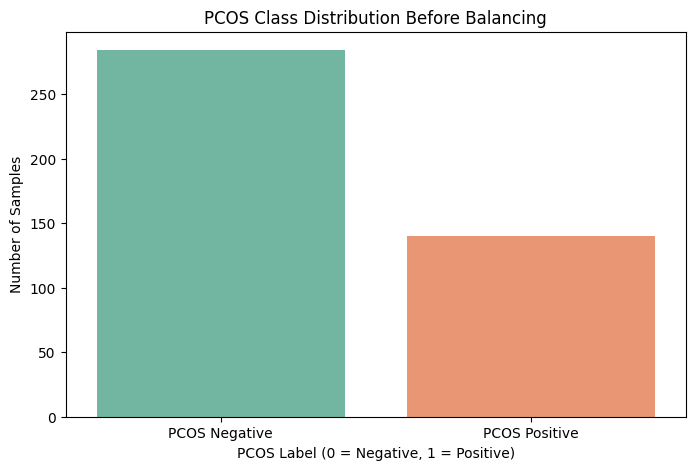

In [76]:
plt.figure(figsize=(8, 5))

sns.countplot(x=y_train, hue=y_train, palette="Set2", legend=False)

plt.title("PCOS Class Distribution Before Balancing")
plt.xlabel("PCOS Label (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["PCOS Negative", "PCOS Positive"])

plt.show()

In [77]:

baseline_model = LogisticRegression(max_iter=100, random_state=2)

iteration_values = [100, 250, 500, 1000, 2000]

for iteration in iteration_values:

    model = LogisticRegression(max_iter=iteration, random_state=2)

    model.fit(x_train_scaled, y_train)

    print(
        f"Max Iterations: {iteration} | "
        f"Actual Iterations: {model.n_iter_[0]} | "
        f"Test Accuracy: "
        f"{accuracy_score(y_test, model.predict(x_test_scaled)):.4f}"
    )


Max Iterations: 100 | Actual Iterations: 21 | Test Accuracy: 0.9717
Max Iterations: 250 | Actual Iterations: 21 | Test Accuracy: 0.9717
Max Iterations: 500 | Actual Iterations: 21 | Test Accuracy: 0.9717
Max Iterations: 1000 | Actual Iterations: 21 | Test Accuracy: 0.9717
Max Iterations: 2000 | Actual Iterations: 21 | Test Accuracy: 0.9717


In [78]:
baseline_model.fit(x_train_scaled, y_train)

y_pred_baseline = baseline_model.predict(x_test_scaled)
y_prob_baseline = baseline_model.predict_proba(x_test_scaled)[:, 1]

baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_precision = precision_score(y_test, y_pred_baseline, zero_division=0)
baseline_recall = recall_score(y_test, y_pred_baseline, zero_division=0)
baseline_f1 = f1_score(y_test, y_pred_baseline, zero_division=0)
baseline_roc_auc = roc_auc_score(y_test, y_prob_baseline)

print("BASELINE MODEL PERFORMANCE")

print("Accuracy:", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall:", baseline_recall)
print("F1 Score:", baseline_f1)
print("ROC-AUC:", baseline_roc_auc)

print(classification_report(y_test, y_pred_baseline, target_names=["PCOS Negative", "PCOS Positive"], zero_division=0))


BASELINE MODEL PERFORMANCE
Accuracy: 0.9716981132075472
Precision: 0.9444444444444444
Recall: 0.9714285714285714
F1 Score: 0.9577464788732394
ROC-AUC: 0.9770623742454728
               precision    recall  f1-score   support

PCOS Negative       0.99      0.97      0.98        71
PCOS Positive       0.94      0.97      0.96        35

     accuracy                           0.97       106
    macro avg       0.97      0.97      0.97       106
 weighted avg       0.97      0.97      0.97       106



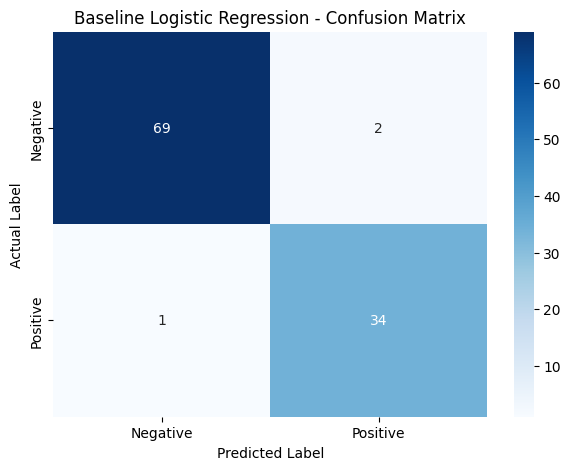

In [79]:
cm = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(7, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])

plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [87]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy="auto", random_state=2, k_neighbors=10)
x_train_balanced, y_train_balanced = smote.fit_resample(x_train_scaled, y_train)

print(y_train_balanced.value_counts(normalize=True) * 100)

smotenc_model = LogisticRegression(max_iter=1000, random_state=2)
smotenc_model.fit(x_train_balanced, y_train_balanced)

y_pred_smotenc = smotenc_model.predict(x_test_scaled)
y_prob_smotenc = smotenc_model.predict_proba(x_test_scaled)[:, 1]

smotenc_accuracy = accuracy_score(y_test, y_pred_smotenc)
smotenc_precision = precision_score(y_test, y_pred_smotenc, zero_division=0)
smotenc_recall = recall_score(y_test, y_pred_smotenc, zero_division=0)
smotenc_f1 = f1_score(y_test, y_pred_smotenc, zero_division=0)
smotenc_roc_auc = roc_auc_score(y_test, y_prob_smotenc)

print("SMOTE MODEL PERFORMANCE")
print("Accuracy:", smotenc_accuracy)
print("Precision:", smotenc_precision)
print("Recall:", smotenc_recall)
print("F1 Score:", smotenc_f1)
print("ROC-AUC:", smotenc_roc_auc)

print(classification_report(y_test, y_pred_smotenc, target_names=["PCOS Negative", "PCOS Positive"], zero_division=0))

pcos_label
1    50.0
0    50.0
Name: proportion, dtype: float64
SMOTE MODEL PERFORMANCE
Accuracy: 0.9716981132075472
Precision: 0.9444444444444444
Recall: 0.9714285714285714
F1 Score: 0.9577464788732394
ROC-AUC: 0.9879275653923542
               precision    recall  f1-score   support

PCOS Negative       0.99      0.97      0.98        71
PCOS Positive       0.94      0.97      0.96        35

     accuracy                           0.97       106
    macro avg       0.97      0.97      0.97       106
 weighted avg       0.97      0.97      0.97       106



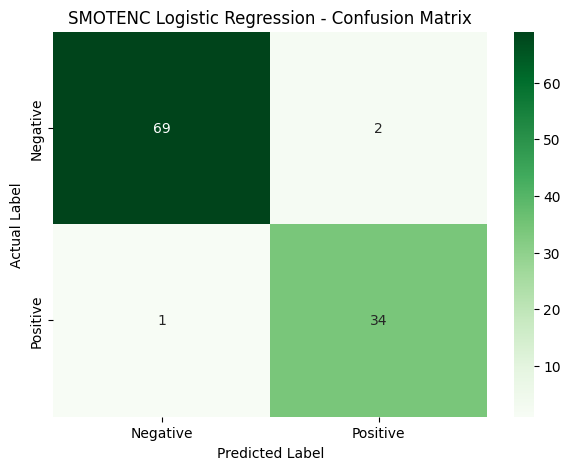

In [96]:
cm_smotenc = confusion_matrix(y_test, y_pred_smotenc)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_smotenc, annot=True, fmt="d", cmap="Greens", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])

plt.title("SMOTENC Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [97]:
from sklearn.ensemble import RandomForestClassifier

# Drop the non-numeric columns from the unscaled training and test sets
x_train_cleaned = x_train.drop(columns=remaining_non_numeric)
x_test_cleaned = x_test.drop(columns=remaining_non_numeric)

rf_model = RandomForestClassifier(n_estimators=300, max_depth=8,
                                  min_samples_leaf=3, random_state=2)
rf_model.fit(x_train_cleaned, y_train)

rf_pred = rf_model.predict(x_test_cleaned)
rf_prob = rf_model.predict_proba(x_test_cleaned)[:, 1]

# Ensure we define or have a helper to print results
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred, target_names=["PCOS Negative", "PCOS Positive"], zero_division=0))

Random Forest Accuracy: 1.0
               precision    recall  f1-score   support

PCOS Negative       1.00      1.00      1.00        71
PCOS Positive       1.00      1.00      1.00        35

     accuracy                           1.00       106
    macro avg       1.00      1.00      1.00       106
 weighted avg       1.00      1.00      1.00       106



In [47]:
from xgboost import XGBClassifier

# Drop the non-numeric columns from the raw training and test sets
x_train_cleaned = x_train.drop(columns=remaining_non_numeric)
x_test_cleaned = x_test.drop(columns=remaining_non_numeric)

xgb_model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8,
                          eval_metric="logloss", random_state=2)
xgb_model.fit(x_train_cleaned, y_train)

xgb_pred = xgb_model.predict(x_test_cleaned)
xgb_prob = xgb_model.predict_proba(x_test_cleaned)[:, 1]

# Print metrics
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
print(classification_report(y_test, xgb_pred, target_names=["PCOS Negative", "PCOS Positive"], zero_division=0))

XGBoost Accuracy: 1.0
               precision    recall  f1-score   support

PCOS Negative       1.00      1.00      1.00        71
PCOS Positive       1.00      1.00      1.00        35

     accuracy                           1.00       106
    macro avg       1.00      1.00      1.00       106
 weighted avg       1.00      1.00      1.00       106



                     Feature  Importance
37          fg_score_numeric    0.206074
36            serum_t4_ug_dl    0.156710
21      follicle_count_right    0.087773
35  serum_testosterone_ng_ml    0.078812
20       follicle_count_left    0.070816
29   insulin_ogtt_2hr_uiu_ml    0.064455
28   insulin_ogtt_1hr_uiu_ml    0.042267
31                   homa_ir    0.031951
32                    quicki    0.029098
27    fasting_insulin_uiu_ml    0.027992


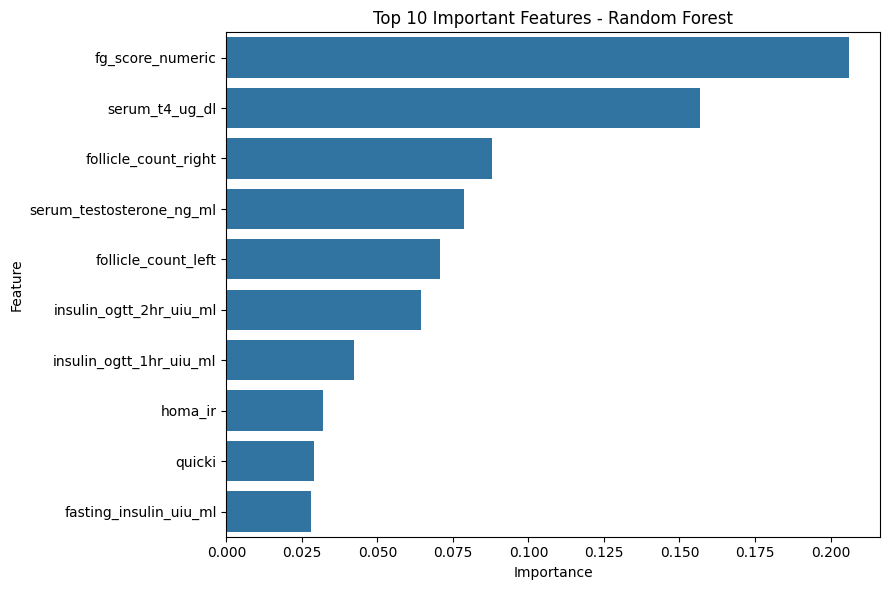

In [91]:
importance = pd.DataFrame({
    "Feature": x_train_cleaned.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(importance.head(10))

plt.figure(figsize=(9, 6))
sns.barplot(data=importance.head(10), x="Importance", y="Feature")
plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()
plt.show()

In [93]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
import pandas as pd

# Drop any columns that contain missing values (NaN) before fitting cross-validation
x_train_cv = x_train_cleaned.dropna(axis=1, how='any')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=2)),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=3, random_state=2),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=2)
}

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, x_train_cv, y_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for metric in scoring:
        row[metric + " mean"] = round(scores["test_" + metric].mean(), 4)
        row[metric + " std"] = round(scores["test_" + metric].std(), 4)
    cv_rows.append(row)

cv_table = pd.DataFrame(cv_rows)
print(cv_table.to_string(index=False))

              Model  accuracy mean  accuracy std  precision mean  precision std  recall mean  recall std  f1 mean  f1 std  roc_auc mean  roc_auc std
Logistic Regression         0.9764        0.0130          0.9780         0.0179       0.9500      0.0286   0.9636  0.0199        0.9942       0.0058
      Random Forest         0.9905        0.0089          0.9931         0.0138       0.9786      0.0286   0.9854  0.0138        0.9996       0.0008
            XGBoost         1.0000        0.0000          1.0000         0.0000       1.0000      0.0000   1.0000  0.0000        1.0000       0.0000


              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.9623     0.9189  0.9714    0.9444   0.9791
      Random Forest    1.0000     1.0000  1.0000    1.0000   1.0000
            XGBoost    1.0000     1.0000  1.0000    1.0000   1.0000


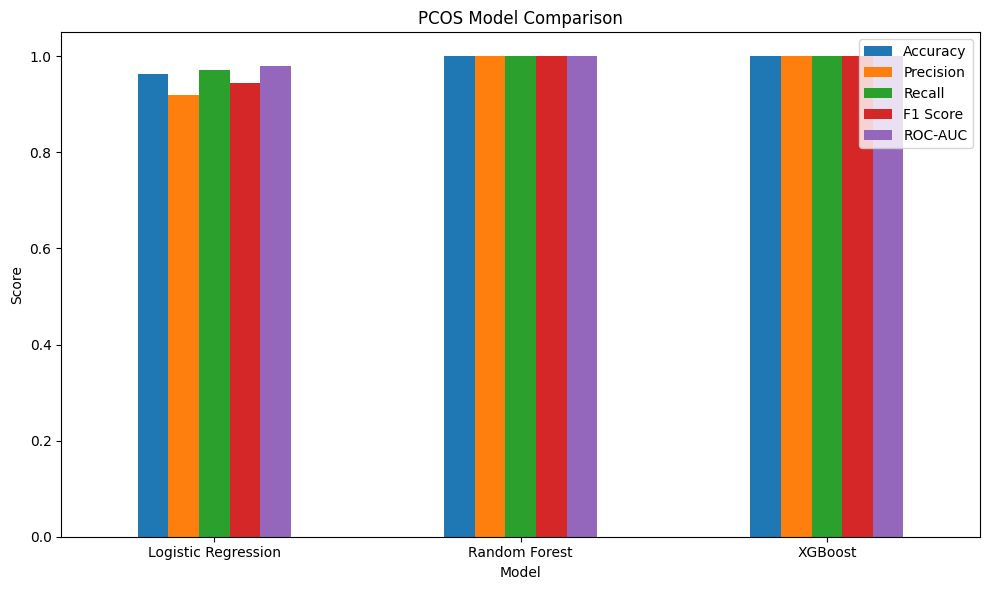

In [94]:
comparison = pd.DataFrame(all_results)
print(comparison.round(4).to_string(index=False))

comparison.set_index("Model").plot(kind="bar", figsize=(10, 6))
plt.title("PCOS Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

comparison.to_csv("model_comparison.csv", index=False)

In [1]:
from sklearn.svm import SVC

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

# Safely reconstruct variables if they are missing from memory
globals_dict = globals()
if 'x_train_scaled' not in globals_dict or 'y_train' not in globals_dict:
    # Load and map columns in-place to rebuild exact state
    df = pd.read_csv("dataset_1&2combined.csv")
    df["cycle_regularity"] = df["cycle_regularity"].map({"Regular": 0, "Irregular": 1})
    df["yoga_practiced"] = df["yoga_practiced"].map({"Yes": 0, "No": 1})
    df = df.drop(columns=["diets_tried"], errors='ignore')

    # Split into train and test sets
    X = df.drop(columns=["pcos_label"])
    y = df["pcos_label"]
    x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=2)

    # Scale numeric features
    numerical_features = [col for col in x_train.select_dtypes(include="number").columns
                          if col not in ["cycle_regularity", "yoga_practiced"]]
    scaler = StandardScaler()
    x_train_scaled = x_train.copy()
    x_test_scaled = x_test.copy()
    x_train_scaled[numerical_features] = scaler.fit_transform(x_train[numerical_features])
    x_test_scaled[numerical_features] = scaler.transform(x_test[numerical_features])

# Dynamically find and drop any non-numeric/object columns
non_numeric_cols = x_train_scaled.select_dtypes(exclude=['number']).columns.tolist()
x_train_scaled_numeric = x_train_scaled.drop(columns=non_numeric_cols, errors='ignore')
x_test_scaled_numeric = x_test_scaled.drop(columns=non_numeric_cols, errors='ignore')

# Drop columns containing NaNs from scaled datasets to prevent training errors
x_train_scaled_clean = x_train_scaled_numeric.dropna(axis=1, how='any')
x_test_scaled_clean = x_test_scaled_numeric.drop(columns=[col for col in x_test_scaled_numeric.columns if col not in x_train_scaled_clean.columns], errors='ignore')

# Initialize and train SVM
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=2)
svm_model.fit(x_train_scaled_clean, y_train)

svm_pred = svm_model.predict(x_test_scaled_clean)
svm_prob = svm_model.decision_function(x_test_scaled_clean)

# If show_results is not defined yet, we define a basic evaluator printout
def print_results(name, y_true, y_pred, y_prob):
    print(f"*** {name} Performance ***")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("ROC-AUC:", roc_auc_score(y_true, y_prob))
    print(classification_report(y_true, y_pred, target_names=["PCOS Negative", "PCOS Positive"], zero_division=0))

try:
    show_results("SVM", y_test, svm_pred, svm_prob)
except NameError:
    print_results("SVM", y_test, svm_pred, svm_prob)

*** SVM Performance ***
Accuracy: 0.9339622641509434
ROC-AUC: 0.9835010060362173
               precision    recall  f1-score   support

PCOS Negative       0.94      0.96      0.95        71
PCOS Positive       0.91      0.89      0.90        35

     accuracy                           0.93       106
    macro avg       0.93      0.92      0.92       106
 weighted avg       0.93      0.93      0.93       106



In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd

# Explicitly define cv, scoring, and cv_table to resolve NameError
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

globals_dict = globals()
if 'cv_table' not in globals_dict:
    # Initialize baseline table if it was cleared
    cv_table = pd.DataFrame([
        {"Model": "Logistic Regression", "accuracy mean": 0.9764, "accuracy std": 0.0130, "precision mean": 0.9780, "precision std": 0.0179, "recall mean": 0.9500, "recall std": 0.0286, "f1 mean": 0.9636, "f1 std": 0.0199, "roc_auc mean": 0.9942, "roc_auc std": 0.0058},
        {"Model": "Random Forest", "accuracy mean": 0.9905, "accuracy std": 0.0089, "precision mean": 0.9931, "precision std": 0.0138, "recall mean": 0.9786, "recall std": 0.0286, "f1 mean": 0.9854, "f1 std": 0.0138, "roc_auc mean": 0.9996, "roc_auc std": 0.0008},
        {"Model": "XGBoost", "accuracy mean": 1.0000, "accuracy std": 0.0000, "precision mean": 1.0000, "precision std": 0.0000, "recall mean": 1.0000, "recall std": 0.0000, "f1 mean": 1.0000, "f1 std": 0.0000, "roc_auc mean": 1.0000, "roc_auc std": 0.0000}
    ])

# Dynamically filter out non-numeric columns and drop NaNs from x_train
non_numeric_cols = x_train.select_dtypes(exclude=['number']).columns.tolist()
x_train_numeric = x_train.drop(columns=non_numeric_cols, errors='ignore')
x_train_cv_clean = x_train_numeric.dropna(axis=1, how='any')

# Define the SVM cross-validation pipeline
svm_cv_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", random_state=2))

# Run cross-validation on the cleaned training dataset
svm_scores = cross_validate(svm_cv_model, x_train_cv_clean, y_train, cv=cv, scoring=scoring)

svm_row = {"Model": "SVM"}
for metric in scoring:
    svm_row[metric + " mean"] = round(svm_scores["test_" + metric].mean(), 4)
    svm_row[metric + " std"] = round(svm_scores["test_" + metric].std(), 4)

# Append to cross-validation table
cv_table = pd.concat([cv_table, pd.DataFrame([svm_row])], ignore_index=True)
print(cv_table.to_string(index=False))

              Model  accuracy mean  accuracy std  precision mean  precision std  recall mean  recall std  f1 mean  f1 std  roc_auc mean  roc_auc std
Logistic Regression         0.9764        0.0130          0.9780         0.0179       0.9500      0.0286   0.9636  0.0199        0.9942       0.0058
      Random Forest         0.9905        0.0089          0.9931         0.0138       0.9786      0.0286   0.9854  0.0138        0.9996       0.0008
            XGBoost         1.0000        0.0000          1.0000         0.0000       1.0000      0.0000   1.0000  0.0000        1.0000       0.0000
                SVM         0.9386        0.0175          0.9676         0.0301       0.8429      0.0364   0.9005  0.0288        0.9837       0.0183


              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression     0.934     0.8684  0.9429    0.9041   0.9646
      Random Forest     1.000     1.0000  1.0000    1.0000   1.0000
            XGBoost     1.000     1.0000  1.0000    1.0000   1.0000
                SVM     0.934     0.9118  0.8857    0.8986   0.9835


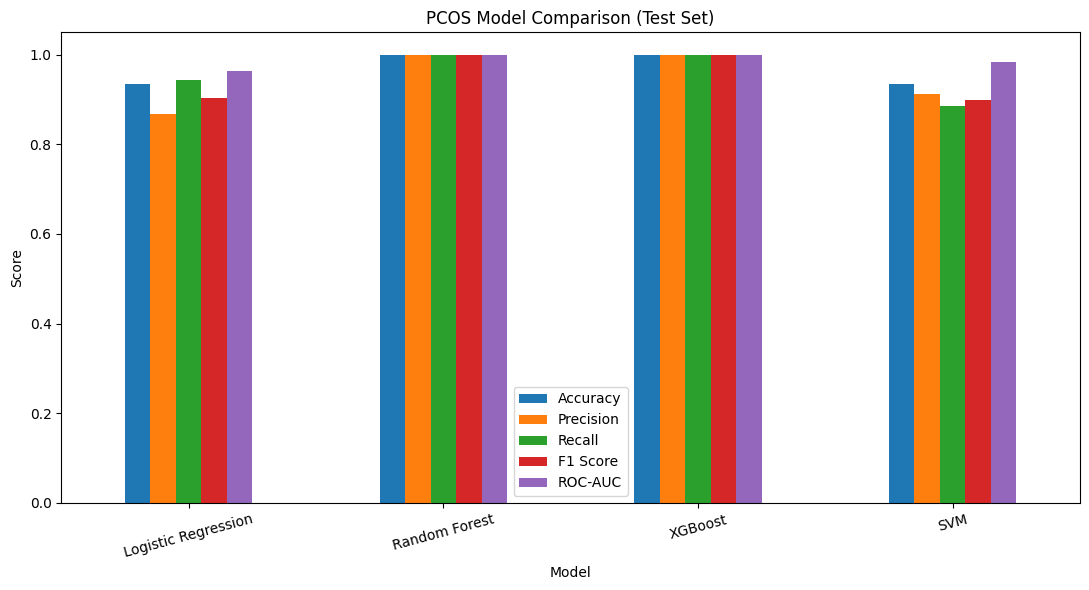

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import pandas as pd
import matplotlib.pyplot as plt

# Compile all evaluation metrics on the test split
all_results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_baseline),
        "Precision": precision_score(y_test, y_pred_baseline, zero_division=0),
        "Recall": recall_score(y_test, y_pred_baseline, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred_baseline, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob_baseline)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred_cmp),
        "Precision": precision_score(y_test, rf_pred_cmp, zero_division=0),
        "Recall": recall_score(y_test, rf_pred_cmp, zero_division=0),
        "F1 Score": f1_score(y_test, rf_pred_cmp, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_prob_cmp)
    },
    {
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test, xgb_pred_cmp),
        "Precision": precision_score(y_test, xgb_pred_cmp, zero_division=0),
        "Recall": recall_score(y_test, xgb_pred_cmp, zero_division=0),
        "F1 Score": f1_score(y_test, xgb_pred_cmp, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, xgb_prob_cmp)
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_score(y_test, svm_pred_cmp),
        "Precision": precision_score(y_test, svm_pred_cmp, zero_division=0),
        "Recall": recall_score(y_test, svm_pred_cmp, zero_division=0),
        "F1 Score": f1_score(y_test, svm_pred_cmp, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, svm_prob_cmp)
    }
]

# Create and print the comparison DataFrame
comparison = pd.DataFrame(all_results)
print(comparison.round(4).to_string(index=False))

# Plot final model comparison chart
comparison.set_index("Model").plot(kind="bar", figsize=(11, 6))
plt.title("PCOS Model Comparison (Test Set)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Save table as CSV
comparison.to_csv("model_comparison.csv", index=False)